Nombre de Courant (CFL) : 0.300 (Doit être <= 0.707)


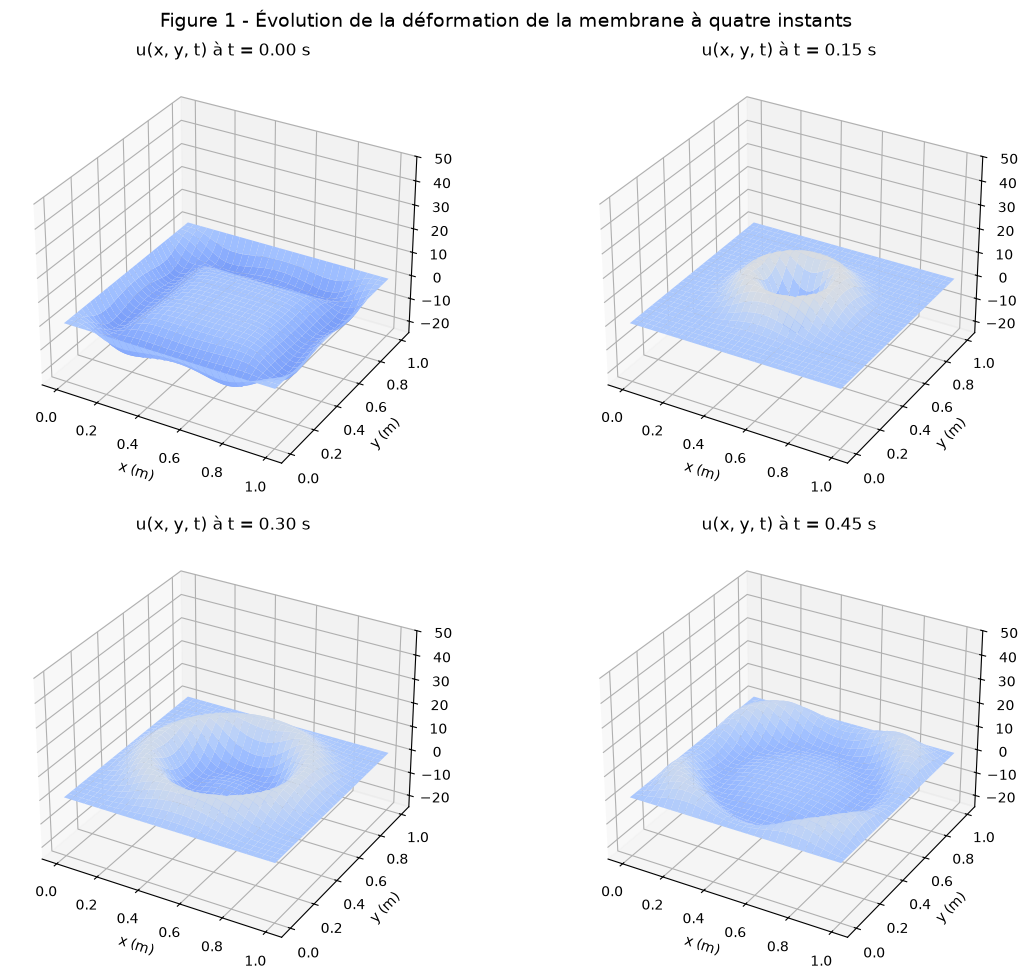

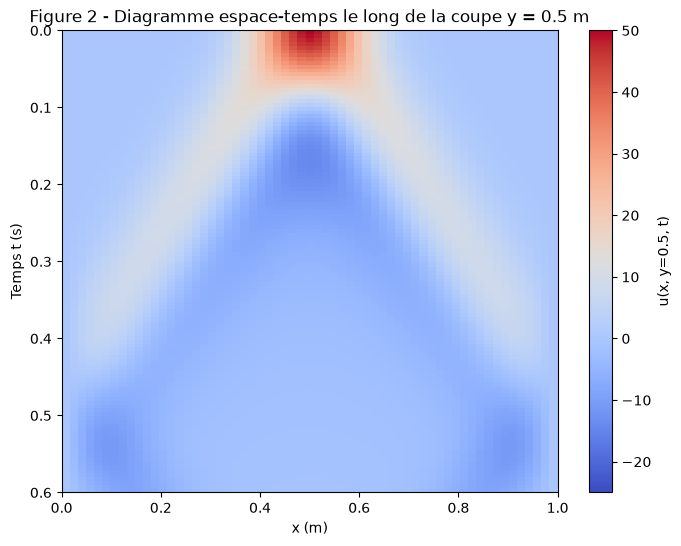

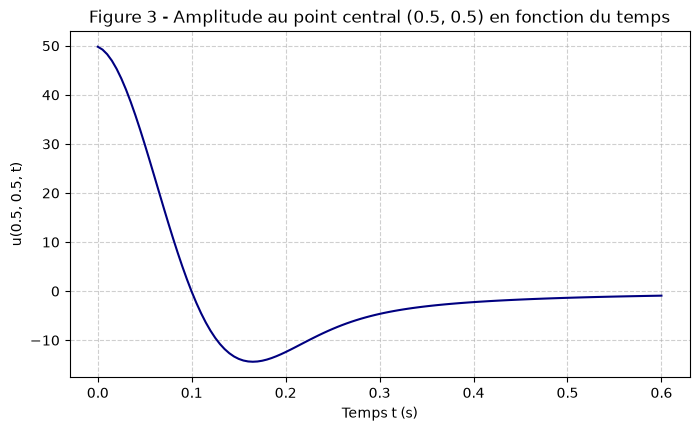

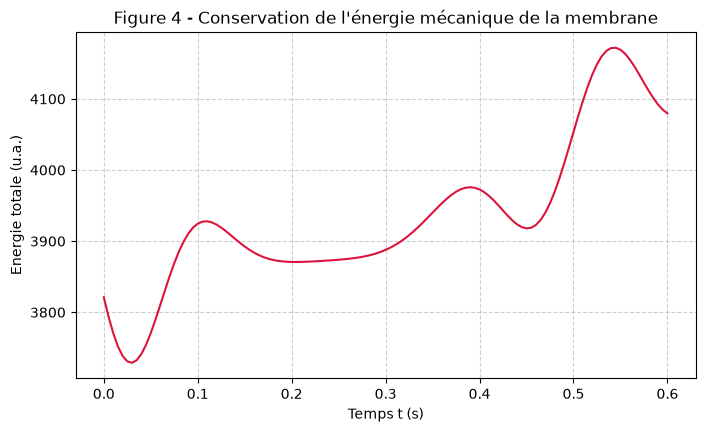

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ==========================================
# 1. PARAMÈTRES DE LA SIMULATION
# ==========================================
L = 1.0            # Taille de la membrane carrée (m)
N = 59             # Nombre de points intérieurs par direction
h = L / (N + 1)    # Pas d'espace
dt = 0.005         # Pas de temps (s)
T_max = 0.6        # Temps total de simulation (s)
n_steps = int(T_max / dt)

# Célérité des ondes (m/s) choisie pour respecter la condition CFL (c*dt/h ≈ 0.3)
c = 1.0 
r = (c * dt / h) ** 2

print(f"Nombre de Courant (CFL) : {c * dt / h:.3f} (Doit être <= 0.707)")

# Grille spatiale
x = np.linspace(0, L, N + 2)
y = np.linspace(0, L, N + 2)
X, Y = np.meshgrid(x, y)
index_center = (N + 2) // 2  # Indice du centre de la membrane

# ==========================================
# 2. CONDITIONS INITIALES ET AUX LIMITES
# ==========================================
# Bosse gaussienne au centre (0.5, 0.5)
x0, y0, sigma = 0.5, 0.5, 0.08
u_prev = 50 * np.exp(-(((X - x0)**2 + (Y - y0)**2) / (2 * sigma**2)))

# Conditions aux limites de Dirichlet (bords fixes = 0)
u_prev[0, :] = 0; u_prev[-1, :] = 0; u_prev[:, 0] = 0; u_prev[:, -1] = 0

# Premier pas de temps (vitesse initiale nulle -> développement de Taylor d'ordre 2)
u_curr = np.copy(u_prev)
laplacian_init = (u_prev[:-2, 1:-1] + u_prev[2:, 1:-1] + 
                  u_prev[1:-1, :-2] + u_prev[1:-1, 2:] - 4 * u_prev[1:-1, 1:-1])
u_curr[1:-1, 1:-1] = u_prev[1:-1, 1:-1] + 0.5 * r * laplacian_init

# Stockage pour les analyses globales
history_center = [u_curr[index_center, index_center]]
time_axis = [0.0]
space_time_slice = [u_curr[:, index_center].copy()]  # Coupe y = 0.5
total_energy = []

# Calcul de l'énergie (cinétique + élastique)
def compute_energy(u_c, u_p, dx, dt_val):
    du_dt = (u_c - u_p) / dt_val
    grad_x, grad_y = np.gradient(u_c, dx)
    e_cinetique = 0.5 * np.sum(du_dt**2) * (dx**2)
    e_elastique = 0.5 * np.sum(grad_x**2 + grad_y**2) * (dx**2)
    return e_cinetique + e_elastique

total_energy.append(compute_energy(u_curr, u_prev, h, dt))

# Instants à afficher pour la Figure 1
times_to_plot = [0.0, 0.15, 0.30, 0.45]
plot_indices = [int(round(t / dt)) for t in times_to_plot]
snapshots = {}

# ==========================================
# 3. BOUCLE TEMPORELLE (Schéma explicite)
# ==========================================
for n in range(1, n_steps + 1):
    u_next = np.zeros_like(u_curr)
    
    # Calcul du Laplacien discret (schéma à 5 points)
    laplacian = (u_curr[:-2, 1:-1] + u_curr[2:, 1:-1] + 
                 u_curr[1:-1, :-2] + u_curr[1:-1, 2:] - 4 * u_curr[1:-1, 1:-1])
    
    # Schéma saute-mouton (leapfrog)
    u_next[1:-1, 1:-1] = 2 * u_curr[1:-1, 1:-1] - u_prev[1:-1, 1:-1] + r * laplacian
    
    # Conditions aux limites (bords fixes)
    u_next[0, :] = 0; u_next[-1, :] = 0; u_next[:, 0] = 0; u_next[:, -1] = 0
    
    # Enregistrement des métriques
    current_t = n * dt
    time_axis.append(current_t)
    history_center.append(u_next[index_center, index_center])
    space_time_slice.append(u_next[:, index_center].copy())
    total_energy.append(compute_energy(u_next, u_curr, h, dt))
    
    if n in plot_indices:
        snapshots[current_t] = np.copy(u_next)
    
    # Mise à jour
    u_prev = np.copy(u_curr)
    u_curr = np.copy(u_next)

# ==========================================
# 4. GÉNÉRATION DES GRAPHIQUES DU RAPPORT
# ==========================================

# --- Figure 1 : Évolution spatiale 3D ---
fig1 = plt.figure(figsize=(12, 10))
fig1.suptitle("Figure 1 - Évolution de la déformation de la membrane à quatre instants", fontsize=14)
for idx, t_val in enumerate(times_to_plot):
    ax = fig1.add_subplot(2, 2, idx + 1, projection='3d')
    data = snapshots.get(t_val, u_prev)
    ax.plot_surface(X, Y, data, cmap='coolwarm', edgecolor='none', vmin=-25, vmax=50)
    ax.set_title(f"u(x, y, t) à t = {t_val:.2f} s")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_zlim(-25, 50)
plt.tight_layout()

# --- Figure 2 : Diagramme espace-temps (coupe y = 0.5 m) ---
plt.figure(figsize=(8, 6))
space_time_matrix = np.array(space_time_slice)
plt.imshow(space_time_matrix, extent=[0, L, T_max, 0], aspect='auto', cmap='coolwarm', vmin=-25, vmax=50)
plt.colorbar(label="u(x, y=0.5, t)")
plt.title("Figure 2 - Diagramme espace-temps le long de la coupe y = 0.5 m")
plt.xlabel("x (m)")
plt.ylabel("Temps t (s)")

# --- Figure 3 : Amplitude au centre de la membrane ---
plt.figure(figsize=(8, 4.5))
plt.plot(time_axis, history_center, color='navy', linewidth=1.5)
plt.title("Figure 3 - Amplitude au point central (0.5, 0.5) en fonction du temps")
plt.xlabel("Temps t (s)")
plt.ylabel("u(0.5, 0.5, t)")
plt.grid(True, linestyle='--', alpha=0.6)

# --- Figure 4 : Conservation de l'énergie mécanique ---
plt.figure(figsize=(8, 4.5))
plt.plot(time_axis, total_energy, color='crimson', linewidth=1.5)
plt.title("Figure 4 - Conservation de l'énergie mécanique de la membrane")
plt.xlabel("Temps t (s)")
plt.ylabel("Energie totale (u.a.)")
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

Nombre de Courant (CFL) : 0.300 (Doit être <= 0.707)


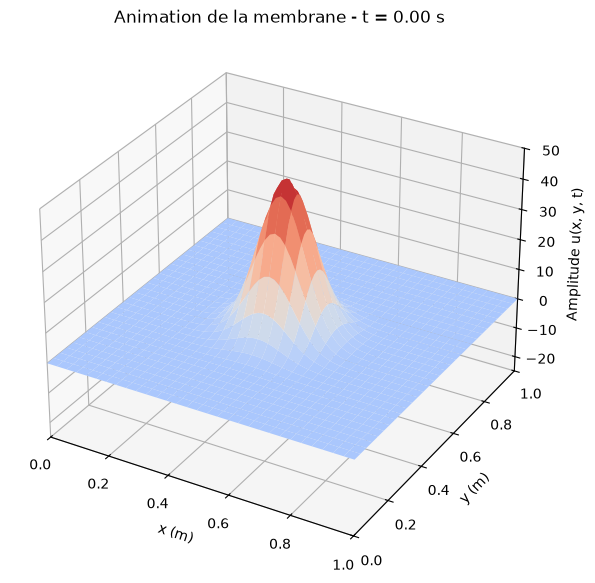

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from mpl_toolkits.mplot3d import Axes3D

# ==========================================
# 1. PARAMÈTRES DE LA SIMULATION
# ==========================================
L = 1.0            # Taille de la membrane carrée (m)
N = 59             # Nombre de points intérieurs par direction
h = L / (N + 1)    # Pas d'espace
dt = 0.005         # Pas de temps (s)
T_max = 0.6        # Temps total de simulation (s)
n_steps = int(T_max / dt)

# Célérité des ondes (m/s) choisie pour respecter la condition CFL
c = 1.0 
r = (c * dt / h) ** 2

print(f"Nombre de Courant (CFL) : {c * dt / h:.3f} (Doit être <= 0.707)")

# Grille spatiale
x = np.linspace(0, L, N + 2)
y = np.linspace(0, L, N + 2)
X, Y = np.meshgrid(x, y)

# ==========================================
# 2. CONDITIONS INITIALES ET AUX LIMITES
# ==========================================
# Bosse gaussienne au centre (0.5, 0.5)
x0, y0, sigma = 0.5, 0.5, 0.08
u_prev = 50 * np.exp(-(((X - x0)**2 + (Y - y0)**2) / (2 * sigma**2)))

# Conditions aux limites de Dirichlet (bords fixes = 0)
u_prev[0, :] = 0; u_prev[-1, :] = 0; u_prev[:, 0] = 0; u_prev[:, -1] = 0

# Premier pas de temps (vitesse initiale nulle -> développement de Taylor d'ordre 2)
u_curr = np.copy(u_prev)
laplacian_init = (u_prev[:-2, 1:-1] + u_prev[2:, 1:-1] + 
                  u_prev[1:-1, :-2] + u_prev[1:-1, 2:] - 4 * u_prev[1:-1, 1:-1])
u_curr[1:-1, 1:-1] = u_prev[1:-1, 1:-1] + 0.5 * r * laplacian_init

# ==========================================
# 3. PRÉPARATION DE LA FIGURE 3D
# ==========================================
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Tracé de la surface initiale
surf = [ax.plot_surface(X, Y, u_curr, cmap='coolwarm', edgecolor='none', vmin=-25, vmax=50)]

ax.set_xlim(0, L)
ax.set_ylim(0, L)
ax.set_zlim(-25, 50)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_zlabel("Amplitude u(x, y, t)")
title = ax.set_title("Animation de la membrane - t = 0.00 s")

# ==========================================
# 4. FONCTION DE MISE À JOUR POUR L'ANIMATION
# ==========================================
state = {'u_prev': u_prev, 'u_curr': u_curr}

def update(frame):
    global state
    u_p = state['u_prev']
    u_c = state['u_curr']
    
    u_next = np.zeros_like(u_c)
    
    # Calcul du Laplacien discret (schéma à 5 points)
    laplacian = (u_c[:-2, 1:-1] + u_c[2:, 1:-1] + 
                 u_c[1:-1, :-2] + u_c[1:-1, 2:] - 4 * u_c[1:-1, 1:-1])
    
    # Schéma saute-mouton (leapfrog)
    u_next[1:-1, 1:-1] = 2 * u_c[1:-1, 1:-1] - u_p[1:-1, 1:-1] + r * laplacian
    
    # Conditions aux limites (bords fixes)
    u_next[0, :] = 0; u_next[-1, :] = 0; u_next[:, 0] = 0; u_next[:, -1] = 0
    
    # Mise à jour des états
    state['u_prev'] = u_c
    state['u_curr'] = u_next
    
    # Redessiner la surface 3D
    surf[0].remove()
    surf[0] = ax.plot_surface(X, Y, u_next, cmap='coolwarm', edgecolor='none', vmin=-25, vmax=50)
    
    current_time = (frame + 1) * dt
    title.set_text(f"Animation de la membrane - t = {current_time:.2f} s")
    
    return surf[0], title

# Lancement de l'animation
anim = FuncAnimation(fig, update, frames=n_steps, interval=30, blit=False)

plt.show()